In [ ]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# A. Fundamentos

## A.1 Problema de negocio

Una empresa de telecomunicaciones pierde clientes todos los meses. A este fenómeno se lo llama **churn** (tasa de cancelación): el porcentaje de clientes que se dan de baja del servicio en un período.

Conseguir un cliente nuevo cuesta bastante más que retener a uno que ya está, por eso a la empresa le interesa entender **quiénes cancelan, por qué lo hacen y cuánto dinero se pierde**. Con esa información puede diseñar acciones de retención dirigidas a los clientes con más riesgo.

**Preguntas que queremos responder:**
1. ¿Qué porcentaje de clientes cancela y cuánto ingreso representa esa pérdida?
2. ¿Qué características del cliente y de su contrato se asocian a una mayor cancelación?
3. ¿Se puede estimar cuánto facturó un cliente en total (`TotalCharges`) a partir de su antigüedad?

**Variable objetivo:** `Churn` (Yes / No), que indica si el cliente canceló el servicio. Para el modelo de regresión vamos a usar además `TotalCharges` (facturación acumulada, en USD).

## A.2 Hipótesis

- **H1.** Los clientes con contrato **mes a mes** cancelan más que los que tienen contrato anual o bianual, porque no tienen compromiso de permanencia.
- **H2.** La cancelación se concentra en los **primeros meses**: los clientes nuevos (con `tenure` bajo) se van más que los antiguos.
- **H3.** Los clientes que pagan **cargos mensuales más altos** cancelan más.
- **H4.** Los clientes que pagan con **cheque electrónico** cancelan más que los que tienen **pago automático** (tarjeta o débito), porque cada mes tienen que decidir pagar.
- **H5.** Los clientes con **fibra óptica** cancelan más que los que tienen DSL.
- **H6.** `TotalCharges` depende fuertemente de `tenure`: cuantos más meses, más facturación acumulada.

## A.3 Clasificación del dataset

El dataset **Telco Customer Churn** es de tipo **estructurado**. Se trata de una tabla en formato CSV con un esquema fijo:

- Cada **fila** representa a un cliente (7.043 en total), identificado por `customerID`.
- Cada **columna** representa un atributo con nombre y tipo de valor definidos (21 columnas).
- Todas las filas tienen las mismas columnas.

No contiene texto libre, imágenes ni audio (que serían datos **no estructurados**), ni estructuras anidadas o flexibles como un JSON o XML (datos **semi-estructurados**). Por eso puede cargarse y manipularse directamente con Pandas.

## A.4 Clasificación de las variables

| Variable | Tipo | Subtipo | dtype en Pandas | ¿Coincide? |
|---|---|---|---|---|
| customerID | Cualitativa | Nominal (identificador) | object | Sí |
| gender | Cualitativa | Nominal (binaria) | object | Sí |
| SeniorCitizen | Cualitativa | Nominal (binaria, codificada 0/1) | int64 | **No** |
| Partner | Cualitativa | Nominal (binaria) | object | Sí |
| Dependents | Cualitativa | Nominal (binaria) | object | Sí |
| tenure | Cuantitativa | Discreta (meses) | int64 | Sí |
| PhoneService | Cualitativa | Nominal (binaria) | object | Sí |
| MultipleLines | Cualitativa | Nominal | object | Sí |
| InternetService | Cualitativa | Nominal | object | Sí |
| OnlineSecurity | Cualitativa | Nominal | object | Sí |
| OnlineBackup | Cualitativa | Nominal | object | Sí |
| DeviceProtection | Cualitativa | Nominal | object | Sí |
| TechSupport | Cualitativa | Nominal | object | Sí |
| StreamingTV | Cualitativa | Nominal | object | Sí |
| StreamingMovies | Cualitativa | Nominal | object | Sí |
| Contract | Cualitativa | Ordinal (mes a mes < 1 año < 2 años) | object | Parcial |
| PaperlessBilling | Cualitativa | Nominal (binaria) | object | Sí |
| PaymentMethod | Cualitativa | Nominal | object | Sí |
| MonthlyCharges | Cuantitativa | Continua (USD) | float64 | Sí |
| TotalCharges | Cuantitativa | Continua (USD) | object | **No** |
| Churn | Cualitativa | Nominal (binaria) — variable objetivo | object | Sí |

**Contraste entre la clasificación teórica y los dtypes de Pandas:**

- **`TotalCharges`** es una variable cuantitativa continua (dinero), pero Pandas la leyó como `object` (texto). Esto indica que la columna contiene algún valor que no es numérico, que analizaremos en la etapa de limpieza.
- **`SeniorCitizen`** es cualitativa (indica si el cliente es adulto mayor o no), pero está codificada con 0 y 1, por lo que Pandas la interpretó como número (`int64`). Tratarla como número sería un error conceptual: por ejemplo, calcular su "promedio" no tiene sentido como cantidad.
- **`Contract`** es ordinal, pero Pandas la guarda como `object`, igual que las nominales. Pandas no distingue entre nominal y ordinal por defecto: para indicar el orden hay que convertirla a una categoría ordenada.
- `tenure` (`int64`) y `MonthlyCharges` (`float64`) coinciden con su tipo teórico.

# B. Limpieza y calidad de datos

In [ ]:
print("Filas duplicadas:", df.duplicated().sum())
print("Clientes repetidos:", df["customerID"].duplicated().sum())
print("Valores nulos por columna:")
df.isna().sum()

Filas duplicadas: 0
Clientes repetidos: 0
Valores nulos por columna:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
vacios = df[df["TotalCharges"].str.strip() == ""]
print("Cantidad de TotalCharges vacíos:", len(vacios))
vacios[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Cantidad de TotalCharges vacíos: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [ ]:
# Elegimos rellenar los espacios con 0
# 1) Convertir la columna a número. Lo que no sea número (los " ") pasa a NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("NaN después de convertir:", df["TotalCharges"].isna().sum())

# 2) Rellenar esos NaN con 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("NaN después de rellenar:", df["TotalCharges"].isna().sum())
print("Tipo de dato ahora:", df["TotalCharges"].dtype)

NaN después de convertir: 11
NaN después de rellenar: 0
Tipo de dato ahora: float64


**Decisión sobre TotalCharges:** se detectaron registros con un espacio en blanco en lugar de un número. Todos corresponden a clientes con `tenure = 0`, es decir, clientes nuevos que aún no fueron facturados. Por eso se imputó el valor **0**, que representa su facturación real. Imputar con la media habría sido incorrecto, porque les asignaría montos que nunca pagaron.

In [ ]:
# SeniorCitizen: de 0/1 a No/Yes, como las otras variables binarias
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Contract: categoría con orden (mes a mes < 1 año < 2 años)
df["Contract"] = pd.Categorical(df["Contract"],
                                categories=["Month-to-month", "One year", "Two year"],
                                ordered=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   object  
 1   gender            7043 non-null   object  
 2   SeniorCitizen     7043 non-null   object  
 3   Partner           7043 non-null   object  
 4   Dependents        7043 non-null   object  
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   object  
 7   MultipleLines     7043 non-null   object  
 8   InternetService   7043 non-null   object  
 9   OnlineSecurity    7043 non-null   object  
 10  OnlineBackup      7043 non-null   object  
 11  DeviceProtection  7043 non-null   object  
 12  TechSupport       7043 non-null   object  
 13  StreamingTV       7043 non-null   object  
 14  StreamingMovies   7043 non-null   object  
 15  Contract          7043 non-null   category
 16  PaperlessBilling  7043 n

# Outliers

In [ ]:
def outliers_iqr(columna):
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    cantidad = ((df[columna] < limite_inf) | (df[columna] > limite_sup)).sum()
    print(f"{columna}: Q1={q1:.2f} | Q3={q3:.2f} | IQR={iqr:.2f} | "
          f"límites=[{limite_inf:.2f} ; {limite_sup:.2f}] | outliers={cantidad}")

for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    outliers_iqr(col)

tenure: Q1=9.00 | Q3=55.00 | IQR=46.00 | límites=[-60.00 ; 124.00] | outliers=0
MonthlyCharges: Q1=35.50 | Q3=89.85 | IQR=54.35 | límites=[-46.02 ; 171.38] | outliers=0
TotalCharges: Q1=398.55 | Q3=3786.60 | IQR=3388.05 | límites=[-4683.52 ; 8868.67] | outliers=0


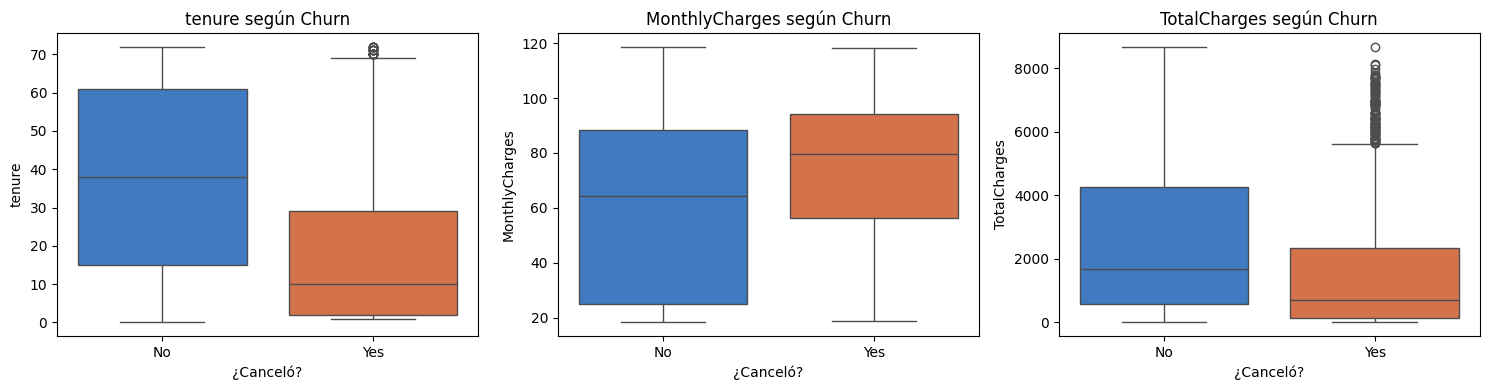

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

colores = {"No": "#2a78d6", "Yes": "#eb6834"}   # azul = se queda, naranja = cancela

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", order=["No", "Yes"], palette=colores, legend=False, ax=ax)
    ax.set_title(f"{col} según Churn")
    ax.set_xlabel("¿Canceló?")

plt.tight_layout()
plt.show()

**Análisis de outliers (método IQR):**

Aplicando el criterio del rango intercuartílico sobre el total de clientes, **no se detectaron valores atípicos** en `tenure`, `MonthlyCharges` ni `TotalCharges`. Todos los valores están dentro de rangos posibles para el negocio (de 0 a 72 meses de antigüedad y cargos mensuales entre ~18 y ~119 USD). Los límites inferiores negativos no tienen interpretación real: indican que no es posible encontrar outliers por debajo.

Al separar por `Churn`, el boxplot muestra algunos puntos aislados en el grupo de clientes que cancelaron (clientes con mucha antigüedad y facturación acumulada alta). Estos valores son atípicos solo **dentro de su grupo**, no en la base completa. **Decidimos conservarlos** porque son clientes reales y válidos, no errores de carga, y representan un caso de interés para el negocio: clientes de alto valor que se perdieron.

**Primeros hallazgos:** los clientes que cancelan tienen mucha menos antigüedad (mediana ≈ 10 meses contra ≈ 38) y cargos mensuales más altos (mediana ≈ 80 USD contra ≈ 64) que los que se quedan, lo que apoya las hipótesis H2 y H3.

# C. Manipulación de datos

In [ ]:
# renombrar columnas
df = df.rename(columns={"customerID": "CustomerID", "gender": "Gender"})
df.columns

Index(['CustomerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
# creando columnas calculadas
import numpy as np

# 1 si canceló, 0 si no (nos va a servir para calcular porcentajes)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

# Antigüedad en años
df["TenureAnios"] = df["tenure"] / 12

# Lo que "debería" haber facturado si siempre hubiera pagado el precio actual
df["TotalChargesEstimado"] = df["tenure"] * df["MonthlyCharges"]

# Cuánto pagó en promedio por mes (si tenure es 0, usamos el cargo mensual para no dividir por cero)
df["CargoPromedio"] = np.where(df["tenure"] > 0,
                               df["TotalCharges"] / df["tenure"],
                               df["MonthlyCharges"])

df[["tenure", "TenureAnios", "MonthlyCharges", "TotalCharges",
    "TotalChargesEstimado", "CargoPromedio", "Churn", "ChurnFlag"]].head()

,tenure,TenureAnios,MonthlyCharges,TotalCharges,TotalChargesEstimado,CargoPromedio,Churn,ChurnFlag
0,1,0.083333,29.85,29.85,29.85,29.850000,No,0
1,34,2.833333,56.95,1889.50,1936.30,55.573529,No,0
2,2,0.166667,53.85,108.15,107.70,54.075000,Yes,1
3,45,3.750000,42.30,1840.75,1903.50,40.905556,No,0
4,2,0.166667,70.70,151.65,141.40,75.825000,Yes,1


In [ ]:
# eliminar columnas
#df = df.drop(columns=["CustomerID"])
#df.shape

In [ ]:
tasa_global = df["ChurnFlag"].mean()
print(f"Tasa de churn general: {tasa_global:.1%} (1 de cada 4 clientes)")

Tasa de churn general: 26.5% (1 de cada 4 clientes)


In [ ]:
alto_riesgo = df[(df["Contract"] == "Month-to-month") &
                 (df["tenure"] <= 12) &
                 (df["MonthlyCharges"] > 70)]

print(f"Clientes de alto riesgo: {len(alto_riesgo)}")
print(f"Su tasa de churn: {alto_riesgo['ChurnFlag'].mean():.1%} (7 de cada 10 se van, Es más de 2,5 veces la tasa general.)")

Clientes de alto riesgo: 856
Su tasa de churn: 69.0% (7 de cada 10 se van, Es más de 2,5 veces la tasa general.)


In [ ]:
fidelizados = df[(df["Contract"] == "Two year") | (df["tenure"] >= 60)]

print(f"Clientes fidelizados: {len(fidelizados)}")
print(f"Su tasa de churn: {fidelizados['ChurnFlag'].mean():.1%} (Casi 5 veces menos que la tasa general.)")

Clientes fidelizados: 2159
Su tasa de churn: 5.4% (Casi 5 veces menos que la tasa general.)


In [ ]:
resumen_contrato = df.groupby("Contract", observed=True).agg(
    Clientes=("ChurnFlag", "count"),
    Cancelaciones=("ChurnFlag", "sum"),
    TasaChurn=("ChurnFlag", "mean"),
    AntiguedadPromedio=("tenure", "mean"),
    CargoMensualPromedio=("MonthlyCharges", "mean"),
    FacturacionTotal=("TotalCharges", "sum"),
)
resumen_contrato.style.format({
    "TasaChurn": "{:.1%}",
    "AntiguedadPromedio": "{:.1f}",
    "CargoMensualPromedio": "${:.2f}",
    "FacturacionTotal": "${:,.0f}",
})

,Clientes,Cancelaciones,TasaChurn,AntiguedadPromedio,CargoMensualPromedio,FacturacionTotal
Contract,,,,,,
Month-to-month,3875,1655,42.7%,18.0,$66.40,"$5,305,862"
One year,1473,166,11.3%,42.0,$65.05,"$4,467,054"
Two year,1695,48,2.8%,56.7,$60.77,"$6,283,254"


**Interpretación de la manipulación de datos:**

- La **tasa de churn general es de 26,5 %**: aproximadamente 1 de cada 4 clientes cancela el servicio.
- El segmento de **alto riesgo** (contrato mes a mes, menos de 12 meses de antigüedad y cargo mensual mayor a 70 USD) reúne 856 clientes con una tasa de churn del **69 %**, más de 2,5 veces la tasa general.
- Los **adultos mayores que pagan con cheque electrónico** (594 clientes) cancelan en un **53,4 %**, el doble de la tasa general.
- En el extremo opuesto, los clientes **fidelizados** (contrato a 2 años o más de 60 meses de antigüedad) tienen un churn de solo **5,4 %**.
- Según el tipo de contrato, el **mes a mes** tiene una tasa de churn del **42,7 %**, contra 11,3 % del contrato anual y 2,8 % del bianual: unas 15 veces más. Además, concentra 1.655 de las 1.869 cancelaciones (cerca del 90 %). Esto **confirma la hipótesis H1**.
- A mayor duración del contrato, mayor antigüedad promedio de los clientes (18, 42 y 57 meses), por lo que los contratos largos son los que más facturación acumulada generan.

In [ ]:
# revisar si lo pide la consigna sino borrar
mayores_cheque = df[(df["SeniorCitizen"] == "Yes") &
                    (df["PaymentMethod"] == "Electronic check")]

print(f"Adultos mayores que pagan con cheque electrónico: {len(mayores_cheque)}")
print(f"Su tasa de churn: {mayores_cheque['ChurnFlag'].mean():.1%}")

Adultos mayores que pagan con cheque electrónico: 594
Su tasa de churn: 53.4%


# D. Análisis exploratorio de datos
## D.1 Análisis cuantitativo

In [ ]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

medidas = pd.DataFrame({
    "Media": df[numericas].mean(),
    "Mediana": df[numericas].median(),
    "Moda": df[numericas].mode().iloc[0],
    "Desvío estándar": df[numericas].std(),
    "Varianza": df[numericas].var(),
    "Mínimo": df[numericas].min(),
    "Máximo": df[numericas].max(),
    "Rango": df[numericas].max() - df[numericas].min(),
    "IQR": df[numericas].quantile(0.75) - df[numericas].quantile(0.25),
    "CV (%)": df[numericas].std() / df[numericas].mean() * 100,
    "Asimetría": df[numericas].skew(),
})
medidas.round(2)

,Media,Mediana,Moda,Desvío estándar,Varianza,Mínimo,Máximo,Rango,IQR,CV (%),Asimetría
tenure,32.37,29.00,1.00,24.56,603.17,0.00,72.00,72.0,46.00,75.87,0.24
MonthlyCharges,64.76,70.35,20.05,30.09,905.41,18.25,118.75,100.5,54.35,46.46,-0.22
TotalCharges,2279.73,1394.55,0.00,2266.79,5138357.17,0.00,8684.80,8684.8,3388.05,99.43,0.96


In [ ]:
df.groupby("Churn")[numericas].agg(["mean", "median", "std"]).round(2)

tenure               MonthlyCharges               TotalCharges           \
        mean median    std           mean median    std         mean   median   
Churn                                                                           
No     37.57   38.0  24.11          61.27  64.43  31.09      2549.91  1679.52   
Yes    17.98   10.0  19.53          74.44  79.65  24.67      1531.80   703.55   

                
           std  
Churn           
No     2329.95  
Yes    1890.82

In [ ]:
variables_corr = ["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]

print("Correlación de Pearson:")
display(df[variables_corr].corr(method="pearson").round(2))

print("Correlación de Spearman:")
display(df[variables_corr].corr(method="spearman").round(2))

Correlación de Pearson:


,tenure,MonthlyCharges,TotalCharges,ChurnFlag
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
ChurnFlag,-0.35,0.19,-0.20,1.00


Correlación de Spearman:


,tenure,MonthlyCharges,TotalCharges,ChurnFlag
tenure,1.00,0.28,0.89,-0.37
MonthlyCharges,0.28,1.00,0.64,0.18
TotalCharges,0.89,0.64,1.00,-0.23
ChurnFlag,-0.37,0.18,-0.23,1.00


**Interpretación del análisis cuantitativo:**

**Tendencia central y dispersión**
- **`tenure`:** la antigüedad media es de 32,4 meses y la mediana de 29. La moda es 1 mes, lo que muestra la gran cantidad de clientes recién incorporados. Tiene una dispersión alta (CV = 76 %): conviven clientes muy nuevos con clientes de hasta 6 años.
- **`MonthlyCharges`:** la mediana (70,35 USD) supera a la media (64,76 USD), con asimetría levemente negativa. Esto se debe a un grupo numeroso de clientes con planes básicos de ~20 USD (la moda), que reduce el promedio.
- **`TotalCharges`:** presenta asimetría positiva (0,96): la media (2.280 USD) es mucho mayor que la mediana (1.395 USD) porque pocos clientes de larga antigüedad acumulan montos muy altos. Es la variable más dispersa (CV = 99 %), por lo que la mediana representa mejor al cliente típico. Su moda (0) corresponde a los clientes nuevos imputados en la limpieza, lo que confirma que la moda es poco informativa en variables continuas.

**Comparación según Churn**
- Los clientes que cancelan tienen una antigüedad mediana de **10 meses**, contra **38** de los que se quedan (**H2**).
- Pagan en promedio **más por mes** (74,44 USD contra 61,27 USD) (**H3**).
- Su facturación acumulada es menor porque permanecen menos tiempo como clientes.

**Correlación**
- **`tenure` – `TotalCharges`:** correlación positiva fuerte (Pearson 0,83; Spearman 0,89). Spearman es mayor porque la relación es creciente pero no perfectamente lineal.
- **`MonthlyCharges` – `TotalCharges`:** correlación positiva moderada (0,65).
- **`tenure` – `MonthlyCharges`:** correlación débil (0,25): la antigüedad y el precio del plan aportan información diferente.
- **Relación con el churn:** `tenure` tiene correlación negativa moderada con `ChurnFlag` (−0,35): a mayor antigüedad, menor cancelación. `MonthlyCharges` tiene una correlación positiva débil (0,19).

Cabe aclarar que **correlación no implica causalidad**: estas relaciones orientan el análisis, pero no prueban que una variable cause a la otra.

## D.2 Análisis categórico

In [ ]:
def frecuencias(columna):
    tabla = pd.DataFrame({
        "Frecuencia absoluta": df[columna].value_counts(),
        "Frecuencia relativa (%)": df[columna].value_counts(normalize=True) * 100, #devuelve proporciones en lugar de cantidades (0,55 en vez de 3.875)
    })
    tabla["Frec. relativa acumulada (%)"] = tabla["Frecuencia relativa (%)"].cumsum()
    return tabla.round(1)

for col in ["Contract", "PaymentMethod", "InternetService", "SeniorCitizen"]:
    print(f"\n===== {col} =====")
    display(frecuencias(col))


===== Contract =====


,Frecuencia absoluta,Frecuencia relativa (%),Frec. relativa acumulada (%)
Contract,,,
Month-to-month,3875,55.0,55.0
Two year,1695,24.1,79.1
One year,1473,20.9,100.0



===== PaymentMethod =====


,Frecuencia absoluta,Frecuencia relativa (%),Frec. relativa acumulada (%)
PaymentMethod,,,
Electronic check,2365,33.6,33.6
Mailed check,1612,22.9,56.5
Bank transfer (automatic),1544,21.9,78.4
Credit card (automatic),1522,21.6,100.0



===== InternetService =====


,Frecuencia absoluta,Frecuencia relativa (%),Frec. relativa acumulada (%)
InternetService,,,
Fiber optic,3096,44.0,44.0
DSL,2421,34.4,78.3
No,1526,21.7,100.0



===== SeniorCitizen =====


,Frecuencia absoluta,Frecuencia relativa (%),Frec. relativa acumulada (%)
SeniorCitizen,,,
No,5901,83.8,83.8
Yes,1142,16.2,100.0


In [ ]:
pd.crosstab(df["Contract"], df["Churn"], margins=True, margins_name="Total")

Churn,No,Yes,Total
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
Total,5174,1869,7043


In [ ]:
(pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100).round(1)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.3,16.7
Credit card (automatic),84.8,15.2
Electronic check,54.7,45.3
Mailed check,80.9,19.1


In [ ]:
variables_cat = ["Gender", "SeniorCitizen", "Partner", "Dependents",          # sociodemográficas
                 "Contract", "PaymentMethod", "InternetService", "PaperlessBilling"]  # contratación

filas = []
for col in variables_cat:
    tasas = df.groupby(col, observed=True)["ChurnFlag"].mean() * 100
    for categoria, tasa in tasas.items():
        filas.append({"Variable": col,
                      "Categoría": categoria,
                      "Clientes": (df[col] == categoria).sum(),
                      "Tasa de churn (%)": round(tasa, 1)})

resumen_categorico = pd.DataFrame(filas)
resumen_categorico

,Variable,Categoría,Clientes,Tasa de churn (%)
0,Gender,Female,3488,26.9
1,Gender,Male,3555,26.2
2,SeniorCitizen,No,5901,23.6
3,SeniorCitizen,Yes,1142,41.7
4,Partner,No,3641,33.0
5,Partner,Yes,3402,19.7
6,Dependents,No,4933,31.3
7,Dependents,Yes,2110,15.5
8,Contract,Month-to-month,3875,42.7
9,Contract,One year,1473,11.3


In [ ]:
from scipy.stats import chi2_contingency

for col in variables_cat:
    tabla = pd.crosstab(df[col], df["Churn"])
    chi2, p_valor, _, _ = chi2_contingency(tabla)
    conclusion = "asociada al churn" if p_valor < 0.05 else "NO asociada"
    print(f"{col:18} p-valor = {p_valor:.4f} -> {conclusion}")

Gender             p-valor = 0.4866 -> NO asociada
SeniorCitizen      p-valor = 0.0000 -> asociada al churn
Partner            p-valor = 0.0000 -> asociada al churn
Dependents         p-valor = 0.0000 -> asociada al churn
Contract           p-valor = 0.0000 -> asociada al churn
PaymentMethod      p-valor = 0.0000 -> asociada al churn
InternetService    p-valor = 0.0000 -> asociada al churn
PaperlessBilling   p-valor = 0.0000 -> asociada al churn


**Interpretación del análisis categórico:**

**Características sociodemográficas**
- **Género:** no muestra asociación con el churn (26,9 % en mujeres y 26,2 % en hombres, casi igual a la tasa general de 26,5 %). No es una variable útil para segmentar acciones de retención.
- **Adultos mayores:** cancelan un 41,7 % contra 23,6 % del resto, casi el doble, aunque representan solo el 16 % de los clientes.
- **Pareja y dependientes:** los clientes sin pareja (33 %) o sin dependientes (31,3 %) cancelan más que quienes los tienen (19,7 % y 15,5 %). Cuando el servicio es compartido por el grupo familiar, el cliente parece estar más "anclado" a la empresa.

**Características de contratación**
- **Tipo de contrato:** es la variable con mayor diferencia entre categorías: 42,7 % en mes a mes, 11,3 % en anual y 2,8 % en bianual (**H1** confirmada).
- **Método de pago:** el cheque electrónico tiene un churn del 45,3 %, unas tres veces mayor que los pagos automáticos (15,2 % y 16,7 %) (**H4** confirmada). El cheque por correo, que también es manual, tiene solo 19,1 %, por lo que el riesgo se asocia específicamente al cheque electrónico.
- **Servicio de internet:** la fibra óptica tiene un churn del 41,9 %, más del doble que DSL (19 %), mientras que los clientes sin internet casi no cancelan (7,4 %) (**H5** confirmada). Esto sugiere revisar el precio o la calidad percibida del servicio de fibra.
- **Factura digital:** quienes la usan cancelan el doble (33,6 % contra 16,3 %). Probablemente no sea una causa directa, sino que estos clientes coinciden más con otros perfiles de riesgo (fibra óptica, cheque electrónico).

## D.3 Visualización de datos

### Gráfico 1: Histogramas con KDE

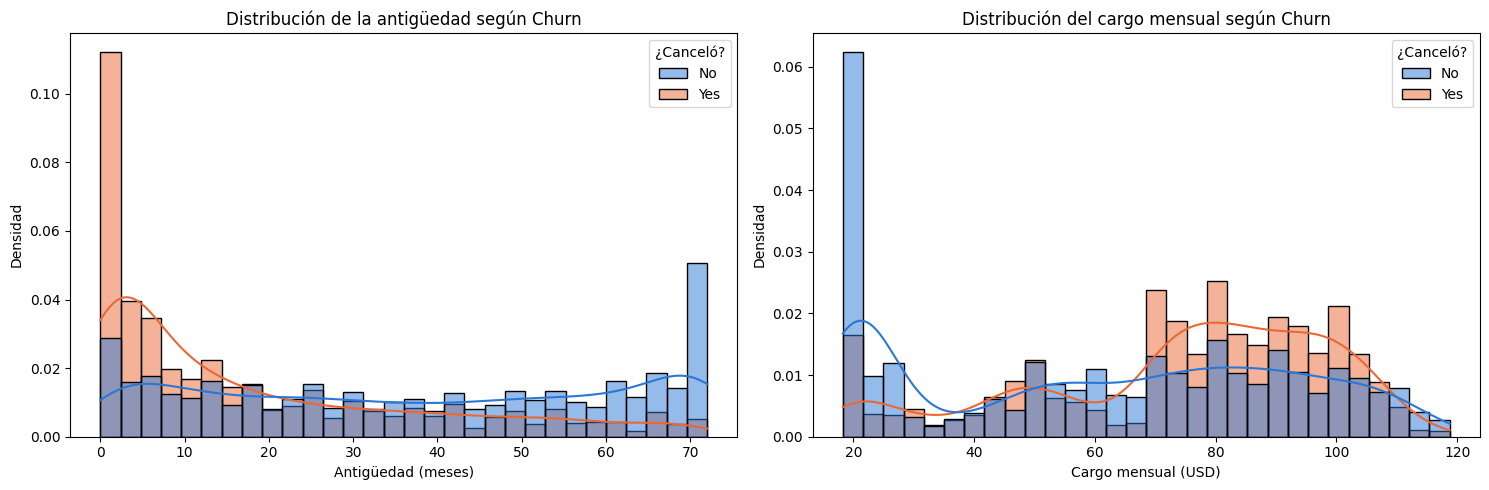

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df, x="tenure", hue="Churn", hue_order=["No", "Yes"], palette=colores,
             bins=30, kde=True, stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Distribución de la antigüedad según Churn")
axes[0].set_xlabel("Antigüedad (meses)")
axes[0].set_ylabel("Densidad")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"], palette=colores,
             bins=30, kde=True, stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Distribución del cargo mensual según Churn")
axes[1].set_xlabel("Cargo mensual (USD)")
axes[1].set_ylabel("Densidad")
axes[0].get_legend().set_title("¿Canceló?")
axes[1].get_legend().set_title("¿Canceló?")

plt.tight_layout()
plt.show()

**Interpretación para el negocio:**

- **Antigüedad:** la distribución de los clientes que permanecen es **bimodal**: tiene un pico de clientes nuevos y otro muy marcado en los 72 meses, que corresponde a los clientes más fieles. En cambio, los clientes que cancelan se concentran fuertemente en los **primeros meses**, con un pico en el primer y segundo mes, y la cancelación disminuye a medida que aumenta la antigüedad (**H2** confirmada).
  → **Impacto:** el primer año, y especialmente los primeros meses, es la **ventana crítica** para la retención. Allí conviene concentrar acciones de bienvenida, seguimiento y beneficios por permanencia.

- **Cargo mensual:** los clientes que permanecen muestran un gran pico cerca de los **20 USD** (planes básicos sin internet), mientras que los que cancelan se concentran entre los **70 y 105 USD**, la franja de los planes más caros, asociados a la fibra óptica (**H3** confirmada).
  → **Impacto:** los clientes de mayor valor son los que más se van. Es necesario revisar la relación precio-calidad de los planes premium, ya que cada cancelación en ese segmento implica una pérdida de ingreso mayor.

### Gráfico 2: Heatmap de la matriz de correlación

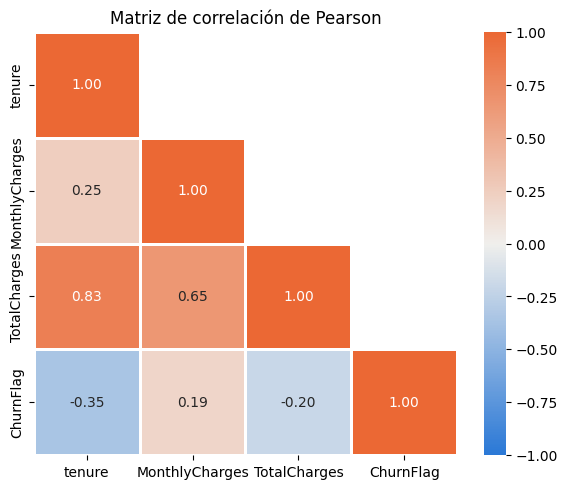

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

escala = LinearSegmentedColormap.from_list("azul_gris_naranja", ["#2a78d6", "#f0efec", "#eb6834"])
matriz = df[["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]].corr(method="pearson")

plt.figure(figsize=(7, 5.5))
mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1)
sns.heatmap(matriz, mask=mascara, annot=True, fmt=".2f", cmap=escala, vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, linecolor="white")
plt.title("Matriz de correlación de Pearson")
plt.show()

**Interpretación para el negocio:**

- La relación más fuerte es entre **antigüedad y facturación total (0,83)**: los clientes que más ingresos generaron son los que más tiempo permanecieron. Esto significa que **cada cliente retenido aumenta su valor con el tiempo**.
- La correlación entre **antigüedad y churn es negativa (−0,35)**, la más fuerte de las variables numéricas con la cancelación: cuanto más tiempo lleva un cliente, menos probable es que se vaya. La fidelidad se construye con el tiempo.
- El **cargo mensual** tiene una correlación positiva débil con el churn (0,19): los planes más caros se asocian a un riesgo algo mayor de cancelación.
- La correlación débil entre **antigüedad y cargo mensual (0,25)** indica que ambas variables aportan información diferente, lo que será útil para el modelo predictivo.

→ **Impacto:** retener a un cliente durante su primer período no solo evita una baja inmediata, sino que lo lleva a la etapa en la que es más fiel y más rentable.

### Gráfico 3: Barras de tasa de churn por contrato y forma de pago

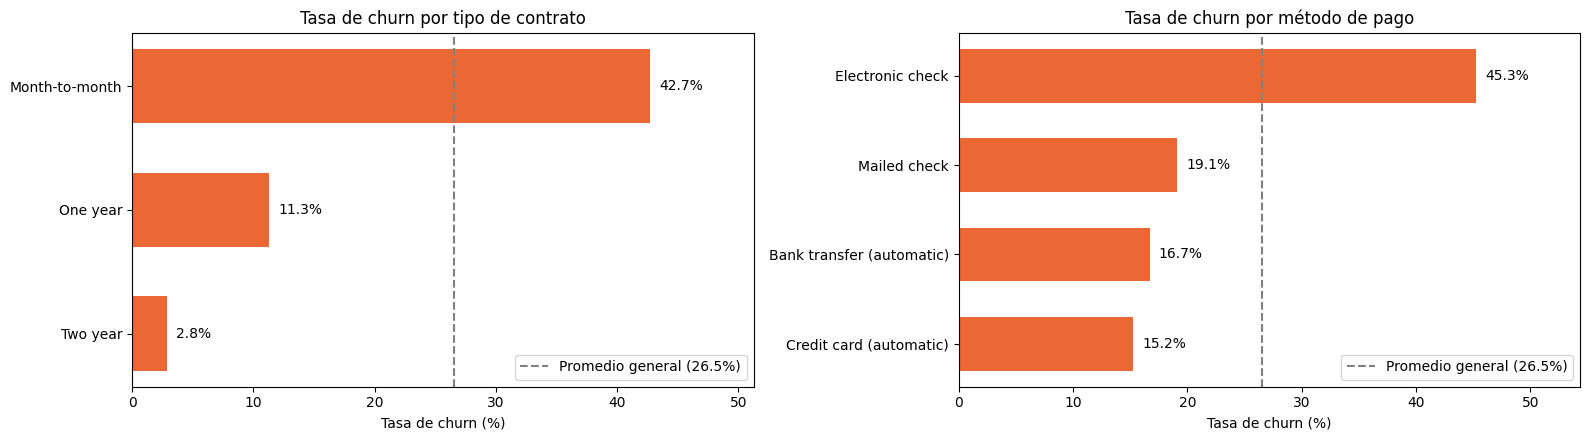

In [ ]:
def grafico_tasa_churn(ax, columna, titulo):
    tasas = df.groupby(columna, observed=True)["ChurnFlag"].mean().sort_values() * 100
    ax.barh(tasas.index.astype(str), tasas.values, color="#eb6834", height=0.6)
    ax.axvline(tasa_global * 100, color="gray", linestyle="--",
               label=f"Promedio general ({tasa_global:.1%})")
    for i, valor in enumerate(tasas.values):
        ax.text(valor + 0.8, i, f"{valor:.1f}%", va="center")
    ax.set_title(titulo)
    ax.set_xlabel("Tasa de churn (%)")
    ax.set_xlim(0, tasas.max() * 1.2)
    ax.legend(loc="lower right")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
grafico_tasa_churn(axes[0], "Contract", "Tasa de churn por tipo de contrato")
grafico_tasa_churn(axes[1], "PaymentMethod", "Tasa de churn por método de pago")
plt.tight_layout()
plt.show()

**Interpretación para el negocio:**

- **Tipo de contrato:** el contrato **mes a mes** tiene una tasa de churn del **42,7 %**, muy por encima del promedio general (26,5 %), mientras que el contrato anual (11,3 %) y el bianual (2,8 %) quedan muy por debajo. El mes a mes cancela unas **15 veces más** que el bianual (**H1** confirmada).
  → **Impacto:** es la palanca de retención más clara. Ofrecer descuentos o beneficios para que los clientes migren de un contrato mes a mes a uno anual o bianual reduciría directamente las cancelaciones.

- **Método de pago:** el **cheque electrónico** es el único método por encima del promedio, con un **45,3 %** de churn, unas **3 veces más** que los pagos automáticos con tarjeta de crédito (15,2 %) o transferencia bancaria (16,7 %) (**H4** confirmada). El cheque por correo, aunque también es manual, tiene solo un 19,1 %.
  → **Impacto:** incentivar la adhesión al **pago automático** (por ejemplo, con una bonificación en la factura) reduciría la fricción mensual del pago y el riesgo de cancelación. Además, conviene investigar si existen problemas específicos con el cheque electrónico.

# E. Preprocesamiento y modelado predictivo
## E.1 Preprocesamiento

In [ ]:
objetivo = "TotalCharges"

numericas_modelo = ["tenure", "MonthlyCharges"]
ordinales = ["Contract"]
nominales = ["Gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
             "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
             "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
             "PaperlessBilling", "PaymentMethod"]

X = df[numericas_modelo + ordinales + nominales]
y = df[objetivo]

print("X:", X.shape, "| y:", y.shape)

X: (7043, 18) | y: (7043,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df["Churn"])

print(f"Entrenamiento: {len(X_train)} clientes | Prueba: {len(X_test)} clientes")

# Verificamos que la proporción de churn sea la misma en los dos conjuntos
print("\n% de churn en la base completa:", round(df["ChurnFlag"].mean() * 100, 2))
print("% de churn en train:", round(df.loc[X_train.index, "ChurnFlag"].mean() * 100, 2))
print("% de churn en test: ", round(df.loc[X_test.index, "ChurnFlag"].mean() * 100, 2))

Entrenamiento: 5634 clientes | Prueba: 1409 clientes

% de churn en la base completa: 26.54
% de churn en train: 26.54
% de churn en test:  26.54


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

preprocesador = ColumnTransformer([
    ("numericas", StandardScaler(), numericas_modelo),
    ("ordinales", OrdinalEncoder(categories=[["Month-to-month", "One year", "Two year"]]), ordinales),
    ("nominales", OneHotEncoder(drop="first", sparse_output=False), nominales),
])

X_train_prep = preprocesador.fit_transform(X_train)   # aprende Y transforma (solo con train)
X_test_prep = preprocesador.transform(X_test)         # solo transforma, con lo aprendido en train

print("Columnas antes:", X_train.shape[1], "→ después:", X_train_prep.shape[1])

X_train_prep_df = pd.DataFrame(X_train_prep, columns=preprocesador.get_feature_names_out())
X_train_prep_df.head()

Columnas antes: 18 → después: 28


,numericas__tenure,numericas__MonthlyCharges,ordinales__Contract,nominales__Gender_Male,nominales__SeniorCitizen_Yes,nominales__Partner_Yes,nominales__Dependents_Yes,nominales__PhoneService_Yes,nominales__MultipleLines_No phone service,nominales__MultipleLines_Yes,...,nominales__TechSupport_No internet service,nominales__TechSupport_Yes,nominales__StreamingTV_No internet service,nominales__StreamingTV_Yes,nominales__StreamingMovies_No internet service,nominales__StreamingMovies_Yes,nominales__PaperlessBilling_Yes,nominales__PaymentMethod_Credit card (automatic),nominales__PaymentMethod_Electronic check,nominales__PaymentMethod_Mailed check
0,0.102371,-0.521976,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.711743,0.337478,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.793155,-0.809013,2.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.263980,0.284384,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0
4,-1.281624,-0.676279,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
X_train_prep_df[["numericas__tenure", "numericas__MonthlyCharges"]].agg(["mean", "std"]).round(2)

,numericas__tenure,numericas__MonthlyCharges
mean,-0.0,-0.0
std,1.0,1.0


## E.2 Modelado: regresión lineal

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

modelo_base = DummyRegressor(strategy="mean")
modelo_base.fit(X_train, y_train)
pred_base = modelo_base.predict(X_test)

print(f"La línea base predice siempre: {pred_base[0]:,.2f} USD")

La línea base predice siempre: 2,299.33 USD


In [ ]:
modelo_simple = LinearRegression()
modelo_simple.fit(X_train[["tenure"]], y_train)        # entrenar (aprender la recta)
pred_simple = modelo_simple.predict(X_test[["tenure"]])  # predecir clientes de test

b0 = modelo_simple.intercept_
b1 = modelo_simple.coef_[0]
print(f"Ecuación: TotalCharges = {b0:,.2f} + {b1:,.2f} × tenure")

Ecuación: TotalCharges = -201.04 + 76.97 × tenure


In [ ]:
modelo_multiple = LinearRegression()
modelo_multiple.fit(X_train_prep, y_train)
pred_multiple = modelo_multiple.predict(X_test_prep)

In [ ]:
#comparando
resultados = pd.DataFrame({
    "Modelo": ["Línea base (promedio)", "Regresión simple (tenure)", "Regresión múltiple"],
    "R² train": [r2_score(y_train, modelo_base.predict(X_train)),
                 r2_score(y_train, modelo_simple.predict(X_train[["tenure"]])),
                 r2_score(y_train, modelo_multiple.predict(X_train_prep))],
    "R² test": [r2_score(y_test, pred_base),
                r2_score(y_test, pred_simple),
                r2_score(y_test, pred_multiple)],
    "MAE test (USD)": [mean_absolute_error(y_test, pred_base),
                       mean_absolute_error(y_test, pred_simple),
                       mean_absolute_error(y_test, pred_multiple)],
})
resultados.round(3)

,Modelo,R² train,R² test,MAE test (USD)
0,Línea base (promedio),0.000,-0.002,1857.566
1,Regresión simple (tenure),0.688,0.657,876.176
2,Regresión múltiple,0.909,0.900,557.686


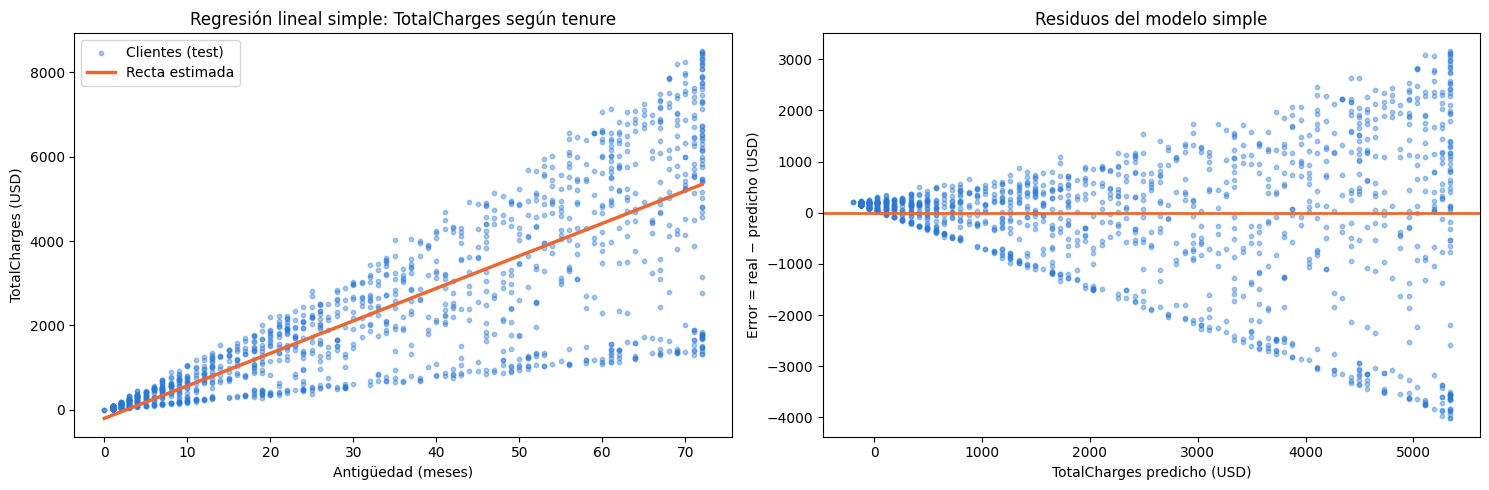

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1) Los datos reales y la recta que aprendió el modelo
axes[0].scatter(X_test["tenure"], y_test, s=10, alpha=0.4, color="#2a78d6", label="Clientes (test)")
x_recta = np.linspace(0, 72, 100)
axes[0].plot(x_recta, b0 + b1 * x_recta, color="#eb6834", linewidth=2.5, label="Recta estimada")
axes[0].set_title("Regresión lineal simple: TotalCharges según tenure")
axes[0].set_xlabel("Antigüedad (meses)")
axes[0].set_ylabel("TotalCharges (USD)")
axes[0].legend()

# 2) Residuos: cuánto se equivocó el modelo en cada cliente
residuos = y_test - pred_simple
axes[1].scatter(pred_simple, residuos, s=10, alpha=0.4, color="#2a78d6")
axes[1].axhline(0, color="#eb6834", linewidth=2)
axes[1].set_title("Residuos del modelo simple")
axes[1].set_xlabel("TotalCharges predicho (USD)")
axes[1].set_ylabel("Error = real − predicho (USD)")

plt.tight_layout()
plt.show()

**Interpretación del modelo de regresión simple:**

- **Ecuación estimada:** TotalCharges = ___ + ___ × tenure. Por cada mes adicional de antigüedad, la facturación acumulada estimada aumenta en aproximadamente ___ USD. El intercepto negativo no tiene interpretación real (un cliente nuevo no puede tener facturación negativa): es una limitación del ajuste lineal en los extremos.

- **Forma de abanico:** la dispersión de los datos aumenta con la antigüedad. Esto ocurre porque la facturación acumulada es aproximadamente el producto de la antigüedad por el cargo mensual: clientes con igual antigüedad pueden haber acumulado montos muy diferentes según su plan. Por ejemplo, con 72 meses, un cliente con plan básico (~20 USD) acumula ~1.500 USD, mientras que uno con plan premium (~118 USD) supera los 8.000 USD.

- **Residuos:** el gráfico de residuos tiene forma de embudo: el error es pequeño para clientes nuevos y crece hasta ±3.000-4.000 USD para los más antiguos. Esto indica **heterocedasticidad** (varianza del error no constante), lo que confirma que `tenure` sola no alcanza para estimar con precisión la facturación de los clientes antiguos.

- **Conclusión:** el modelo múltiple mejora notablemente (R² de 0,66 a 0,90) porque incorpora el cargo mensual, que permite distinguir el nivel de gasto de cada cliente. Aun así, no alcanza un ajuste perfecto porque la relación real es multiplicativa (antigüedad × cargo mensual) y la regresión lineal modela efectos aditivos.

# F. Conclusiones y recomendaciones

## F.1 Validación de hipótesis

| Hipótesis | Resultado | Evidencia |
|---|---|---|
| **H1.** El contrato mes a mes tiene más churn | ✅ Confirmada | 42,7 % de churn contra 11,3 % (anual) y 2,8 % (bianual) |
| **H2.** El churn se concentra en los primeros meses | ✅ Confirmada | Mediana de antigüedad de 10 meses en quienes cancelan contra 38 en quienes permanecen |
| **H3.** Los cargos mensuales altos se asocian a más churn | ✅ Confirmada | Quienes cancelan pagan en promedio 74 USD contra 61 USD; se concentran entre 70 y 105 USD |
| **H4.** El pago con cheque electrónico tiene más churn | ✅ Confirmada | 45,3 % contra 15-17 % de los pagos automáticos |
| **H5.** La fibra óptica tiene más churn que DSL | ✅ Confirmada | 41,9 % contra 19 % |
| **H6.** `TotalCharges` depende fuertemente de `tenure` | ⚠️ Parcialmente | La antigüedad explica el 66 % de la variación; el resto depende del cargo mensual |

## F.2 Hallazgos principales

1. **Uno de cada cuatro clientes cancela** (26,5 %), y la cancelación está muy concentrada en perfiles identificables.
2. **El tipo de contrato es el factor más determinante:** el contrato mes a mes concentra cerca del 90 % de las cancelaciones.
3. **El riesgo es máximo al comienzo de la relación comercial:** una vez superado el primer año, la probabilidad de cancelación cae fuertemente.
4. **Se identificó un segmento de alto riesgo** (contrato mes a mes, menos de 12 meses y cargo mensual mayor a 70 USD) con un churn del **69 %**. Los adultos mayores que pagan con cheque electrónico también presentan un riesgo muy elevado (**53,4 %**).
5. **El género no influye** en la cancelación, por lo que no es una variable útil para segmentar acciones de retención.

## F.3 Recomendaciones para el negocio

1. **Migración de contratos:** ofrecer descuentos o beneficios a los clientes con contrato mes a mes para pasar a contratos anuales o bianuales, comenzando por los de mayor cargo mensual.
2. **Programa de bienvenida durante el primer año:** realizar seguimiento proactivo en los primeros meses (contacto inicial, verificación de la calidad del servicio, beneficios por permanencia).
3. **Incentivar el pago automático:** bonificar la adhesión a débito automático o tarjeta de crédito para reducir el uso del cheque electrónico.
4. **Revisar el servicio de fibra óptica:** analizar su precio frente a la competencia, la calidad técnica y los reclamos, ya que es el servicio más caro y el que más cancelaciones presenta.
5. **Priorizar el segmento de alto riesgo** en las campañas de retención, por concentrar la mayor probabilidad de cancelación.

## F.4 Limitaciones y próximos pasos

- **Correlación no implica causalidad:** los factores identificados se asocian al churn, pero el análisis no prueba que lo causen. Las acciones recomendadas deberían evaluarse con pruebas piloto.
- **Datos de un único momento:** el dataset no permite analizar la evolución de los clientes en el tiempo ni conocer los motivos declarados de cancelación.
- **Modelo de regresión:** la regresión lineal no capta completamente la relación multiplicativa entre antigüedad y cargo mensual.
- **Próximo paso:** construir un modelo de **clasificación** (por ejemplo, regresión logística) que estime la **probabilidad de churn** de cada cliente, para priorizar a quién contactar primero en las campañas de retención.